<a href="https://colab.research.google.com/github/priyatosh871-cloud/Introduction-To-AI-Lab/blob/main/ai%20lab%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 1. Define the Graph using an Adjacency List

In [15]:
graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': [],
    'F': []
}

print("Graph (Adjacency List):")
for node, neighbors in graph.items():
    print(f"{node}: {neighbors}")

Graph (Adjacency List):
A: ['B', 'C']
B: ['D', 'E']
C: ['F']
D: []
E: []
F: []


### 2. Breadth-First Search (BFS) Traversal

In [16]:
from collections import deque

def bfs(graph, start_node):
    visited = set()  # To keep track of visited nodes
    queue = deque([start_node])  # Initialize queue with the starting node
    bfs_order = []  # To store the traversal order

    visited.add(start_node)

    while queue:
        current_node = queue.popleft() # Dequeue a node
        bfs_order.append(current_node)

        # Add all unvisited neighbors to the queue
        for neighbor in graph.get(current_node, []):
            if neighbor not in visited:
                visited.add(neighbor)
                queue.append(neighbor)
    return bfs_order

# Perform BFS starting from node 'A'
bfs_traversal_order = bfs(graph, 'A')
print(f"BFS Traversal Order: {bfs_traversal_order}")

BFS Traversal Order: ['A', 'B', 'C', 'D', 'E', 'F']


### 3. Depth-First Search (DFS) Traversal

In [17]:
def dfs(graph, start_node):
    visited = set()  # To keep track of visited nodes
    dfs_order = []  # To store the traversal order

    def dfs_recursive(node):
        visited.add(node)
        dfs_order.append(node)
        for neighbor in graph.get(node, []):
            if neighbor not in visited:
                dfs_recursive(neighbor)

    dfs_recursive(start_node)
    return dfs_order

# Perform DFS starting from node 'A'
dfs_traversal_order = dfs(graph, 'A')
print(f"DFS Traversal Order: {dfs_traversal_order}")

DFS Traversal Order: ['A', 'B', 'D', 'E', 'C', 'F']


### 4. Visualize Traversal Orders

We'll use `networkx` to represent the graph and `matplotlib` to draw it, coloring nodes based on their visit order during BFS and DFS.

In [18]:
import matplotlib.pyplot as plt
import networkx as nx

# Create a directed graph for visualization
G = nx.DiGraph(graph)

# Define positions for a nice tree layout
pos = {
    'A': (0, 2),
    'B': (-1, 1),
    'C': (1, 1),
    'D': (-1.5, 0),
    'E': (-0.5, 0),
    'F': (1, 0)
}

# Helper function to get node colors based on traversal order
def get_node_colors(traversal_order, all_nodes):
    color_map = {}
    for i, node in enumerate(traversal_order):
        # Assign a color based on order (e.g., darker for earlier visits)
        color_map[node] = plt.cm.viridis(i / len(traversal_order))
    # For nodes not visited (if any, though not in this tree example), assign a default color
    for node in all_nodes:
        if node not in color_map:
            color_map[node] = 'lightgray'
    return [color_map[node] for node in all_nodes]

all_graph_nodes = list(G.nodes())

#### BFS Traversal Diagram

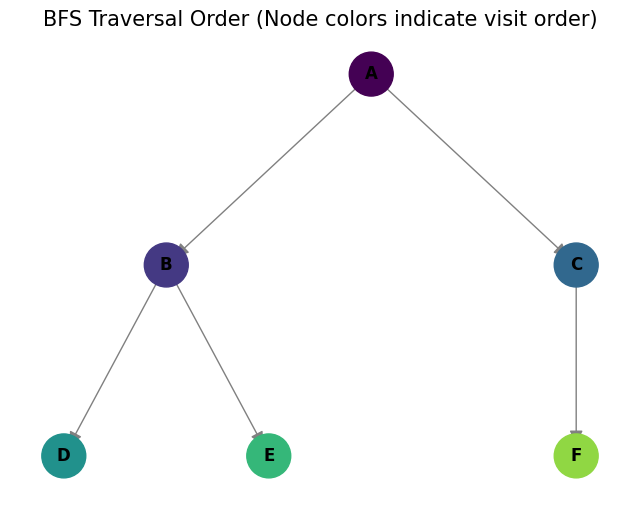

In [19]:
# Get colors for BFS traversal
bfs_colors = get_node_colors(bfs_traversal_order, all_graph_nodes)

plt.figure(figsize=(8, 6))
nx.draw_networkx_nodes(G, pos, node_color=bfs_colors, node_size=1000)
nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=20)
nx.draw_networkx_labels(G, pos, font_size=12, font_weight='bold')
plt.title('BFS Traversal Order (Node colors indicate visit order)', size=15)
plt.axis('off')
plt.show()

#### DFS Traversal Diagram

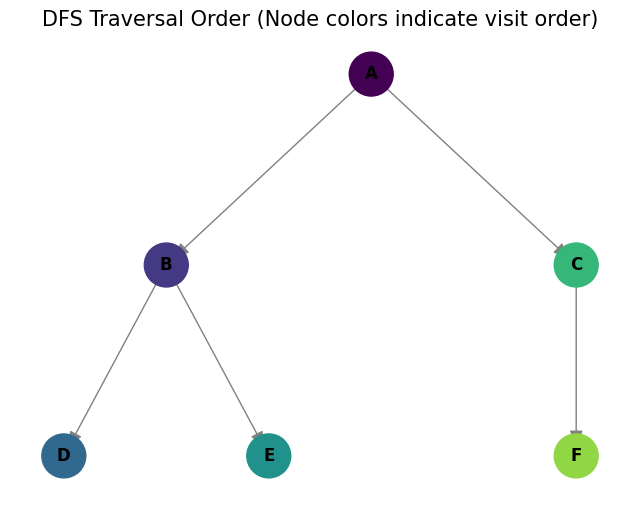

In [20]:
# Get colors for DFS traversal
dfs_colors = get_node_colors(dfs_traversal_order, all_graph_nodes)

plt.figure(figsize=(8, 6))
nx.draw_networkx_nodes(G, pos, node_color=dfs_colors, node_size=1000)
nx.draw_networkx_edges(G, pos, edge_color='gray', arrows=True, arrowsize=20)
nx.draw_networkx_labels(G, pos, font_size=12, font_weight='bold')
plt.title('DFS Traversal Order (Node colors indicate visit order)', size=15)
plt.axis('off')
plt.show()

## Problem 2: The Water Jug Problem (Solved using BFS)

### Problem Statement:

You are given two jugs: Jug A with a capacity of 4 litres, and Jug B with a capacity of 3 litres. Neither jug has any markings on it. Using only the following operations — (i) fill a jug completely, (ii) empty a jug completely, (iii) pour water from one jug into the other until either the first jug is empty or the second jug is full — determine the minimum sequence of steps needed to measure out exactly 2 litres of water in any one jug.

### Approach:

We can model this problem as a state-space search problem. Each state is defined by the amount of water in Jug A and Jug B, represented as a tuple `(water_in_A, water_in_B)`. We'll use Breadth-First Search (BFS) because it guarantees finding the shortest path (minimum number of steps) from the initial state `(0, 0)` to the goal state (2 litres in either jug).

**Operations:**
1.  Fill Jug A
2.  Fill Jug B
3.  Empty Jug A
4.  Empty Jug B
5.  Pour water from Jug A to Jug B
6.  Pour water from Jug B to Jug A

In [21]:
from collections import deque

# Define jug capacities
CAP_A = 4 # Capacity of Jug A
CAP_B = 3 # Capacity of Jug B

# Goal amount
GOAL = 2

def get_next_states(state):
    current_A, current_B = state
    next_states = []

    # 1. Fill Jug A
    if current_A < CAP_A:
        next_states.append((CAP_A, current_B))
    # 2. Fill Jug B
    if current_B < CAP_B:
        next_states.append((current_A, CAP_B))
    # 3. Empty Jug A
    if current_A > 0:
        next_states.append((0, current_B))
    # 4. Empty Jug B
    if current_B > 0:
        next_states.append((current_A, 0))

    # 5. Pour A to B
    if current_A > 0 and current_B < CAP_B:
        pour_amount = min(current_A, CAP_B - current_B)
        next_states.append((current_A - pour_amount, current_B + pour_amount))
    # 6. Pour B to A
    if current_B > 0 and current_A < CAP_A:
        pour_amount = min(current_B, CAP_A - current_A)
        next_states.append((current_A + pour_amount, current_B - pour_amount))

    return next_states

def bfs_water_jug(start_state, goal_amount):
    queue = deque([(start_state, [start_state])]) # (current_state, path_to_current_state)
    visited = {start_state}

    while queue:
        current_state, path = queue.popleft()
        current_A, current_B = current_state

        # Check if goal is reached
        if current_A == goal_amount or current_B == goal_amount:
            return path

        for next_state in get_next_states(current_state):
            if next_state not in visited:
                visited.add(next_state)
                queue.append((next_state, path + [next_state]))
    return None # No solution found

# Solve the problem
solution_path = bfs_water_jug((0, 0), GOAL)

if solution_path:
    print(f"Solution found in {len(solution_path) - 1} steps:")
    for i, state in enumerate(solution_path):
        print(f"Step {i}: Jug A: {state[0]}L, Jug B: {state[1]}L")
else:
    print("No solution found.")

Solution found in 4 steps:
Step 0: Jug A: 0L, Jug B: 0L
Step 1: Jug A: 0L, Jug B: 3L
Step 2: Jug A: 3L, Jug B: 0L
Step 3: Jug A: 3L, Jug B: 3L
Step 4: Jug A: 4L, Jug B: 2L


### Visualize the Water Jug Solution

We will visualize the state space of the water jug problem as a graph, where each node is a state `(Jug A, Jug B)` and edges represent valid transitions. The shortest path found by BFS will be highlighted.

Drawing graph with solution path highlighted...


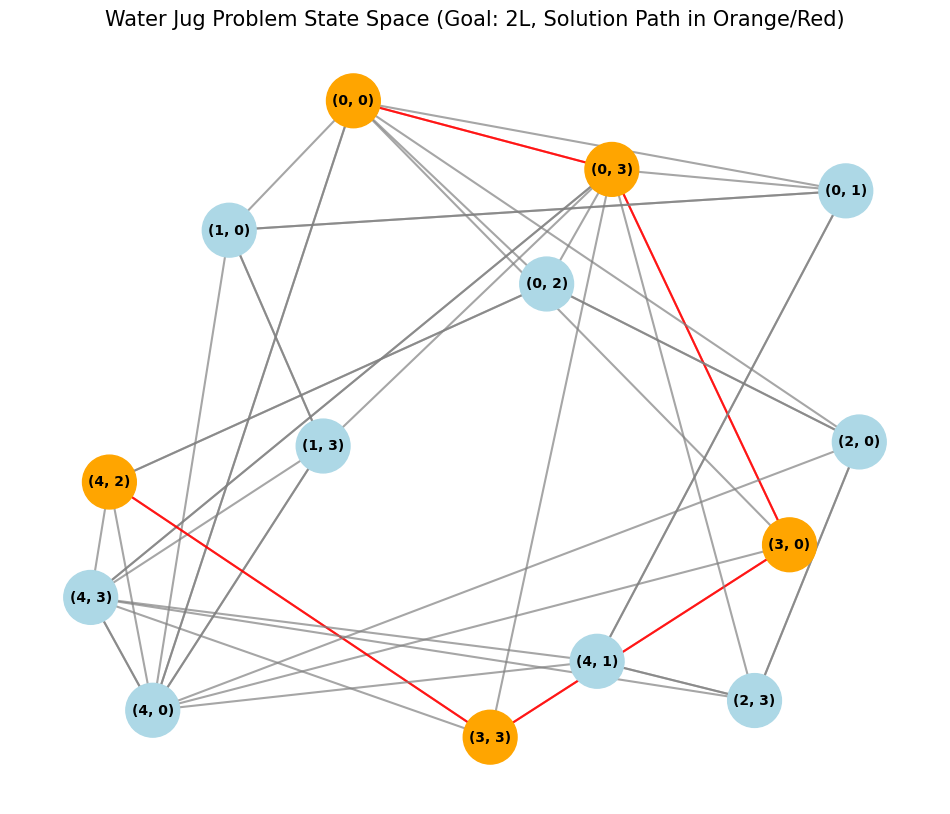

In [22]:
import matplotlib.pyplot as plt
import networkx as nx

def create_water_jug_graph(cap_a, cap_b):
    G = nx.DiGraph()
    q = deque([(0, 0)])
    visited = {(0, 0)}

    while q:
        current_state = q.popleft()
        G.add_node(current_state)

        for next_state in get_next_states(current_state):
            if next_state not in visited:
                visited.add(next_state)
                q.append(next_state)
            G.add_edge(current_state, next_state)
    return G

# Create the graph of all possible states
water_jug_graph = create_water_jug_graph(CAP_A, CAP_B)

# Define node positions for better visualization (can be tricky for complex graphs)
# For simplicity, we'll try a basic layout for now.
pos = nx.spring_layout(water_jug_graph, k=0.5, iterations=50) # Use a spring layout

# Prepare for drawing
node_colors = ['lightblue' for _ in water_jug_graph.nodes()]
edge_colors = ['gray' for _ in water_jug_graph.edges()]
path_edges = []

# Highlight the solution path if found
if solution_path:
    print("Drawing graph with solution path highlighted...")
    # Color the nodes in the solution path
    for i, node in enumerate(water_jug_graph.nodes()):
        if node in solution_path:
            node_colors[list(water_jug_graph.nodes()).index(node)] = 'orange'
    # Color the edges in the solution path
    for i in range(len(solution_path) - 1):
        u = solution_path[i]
        v = solution_path[i+1]
        if (u, v) in water_jug_graph.edges():
            path_edges.append((u,v))
        else:
            # Handle cases where networkx might reverse edge direction during internal representation
            path_edges.append((v,u))

    # Update edge colors for the path
    for i, edge in enumerate(water_jug_graph.edges()):
        if edge in path_edges or (edge[1], edge[0]) in path_edges: # Check both directions for undirected path visualization
            edge_colors[i] = 'red'

plt.figure(figsize=(12, 10))
nx.draw_networkx_nodes(water_jug_graph, pos, node_color=node_colors, node_size=1500)
nx.draw_networkx_edges(water_jug_graph, pos, edge_color=edge_colors, width=1.5, alpha=0.7, arrows=True, arrowsize=20)
nx.draw_networkx_labels(water_jug_graph, pos, font_size=10, font_weight='bold')

plt.title(f"Water Jug Problem State Space (Goal: {GOAL}L, Solution Path in Orange/Red)", size=15)
plt.axis('off')
plt.show()

## Problem 3: Checking Routes Between Cities Using DFS

### Problem Statement:

A small road network connects several cities. Write a Python program using DFS that:
1. Checks whether a route exists between two given cities.
2. Finds all separate groups of cities that are connected to each other but not to any other group (these are called connected components). using matplotlib

### 1. Define the City Road Network

In [23]:
city_graph = {
    'London': ['Paris', 'Berlin'],
    'Paris': ['London', 'Rome'],
    'Berlin': ['London', 'Warsaw'],
    'Rome': ['Paris'],
    'Warsaw': ['Berlin', 'Kyiv'],
    'Kyiv': ['Warsaw'],
    'Madrid': ['Lisbon'],
    'Lisbon': ['Madrid'],
    'Dublin': []
}

print("City Road Network (Adjacency List):")
for city, connected_cities in city_graph.items():
    print(f"{city}: {connected_cities}")

City Road Network (Adjacency List):
London: ['Paris', 'Berlin']
Paris: ['London', 'Rome']
Berlin: ['London', 'Warsaw']
Rome: ['Paris']
Warsaw: ['Berlin', 'Kyiv']
Kyiv: ['Warsaw']
Madrid: ['Lisbon']
Lisbon: ['Madrid']
Dublin: []


### 2. Check for a Route Between Two Cities (DFS)

In [24]:
def check_route_dfs(graph, start, end):
    visited = set()
    stack = [start]

    while stack:
        current_city = stack.pop()
        if current_city == end:
            return True
        if current_city not in visited:
            visited.add(current_city)
            for neighbor in graph.get(current_city, []):
                if neighbor not in visited:
                    stack.append(neighbor)
    return False

# Example usage:
city1, city2 = 'London', 'Kyiv'
if check_route_dfs(city_graph, city1, city2):
    print(f"A route exists between {city1} and {city2}.")
else:
    print(f"No route exists between {city1} and {city2}.")

city3, city4 = 'London', 'Madrid'
if check_route_dfs(city_graph, city3, city4):
    print(f"A route exists between {city3} and {city4}.")
else:
    print(f"No route exists between {city3} and {city4}.")

A route exists between London and Kyiv.
No route exists between London and Madrid.


### 3. Find Connected Components (DFS)

In [25]:
def find_connected_components_dfs(graph):
    visited = set()
    connected_components = []

    for city in graph:
        if city not in visited:
            current_component = []
            stack = [city]
            component_visited = set()

            while stack:
                current_node = stack.pop()
                if current_node not in component_visited:
                    component_visited.add(current_node)
                    visited.add(current_node) # Mark as globally visited
                    current_component.append(current_node)
                    for neighbor in graph.get(current_node, []):
                        if neighbor not in component_visited:
                            stack.append(neighbor)
            if current_component:
                connected_components.append(sorted(current_component))
    return connected_components

connected_components = find_connected_components_dfs(city_graph)
print("Connected Components:")
for i, component in enumerate(connected_components):
    print(f"Component {i+1}: {component}")

Connected Components:
Component 1: ['Berlin', 'Kyiv', 'London', 'Paris', 'Rome', 'Warsaw']
Component 2: ['Lisbon', 'Madrid']
Component 3: ['Dublin']


### 4. Visualize the City Network and Connected Components

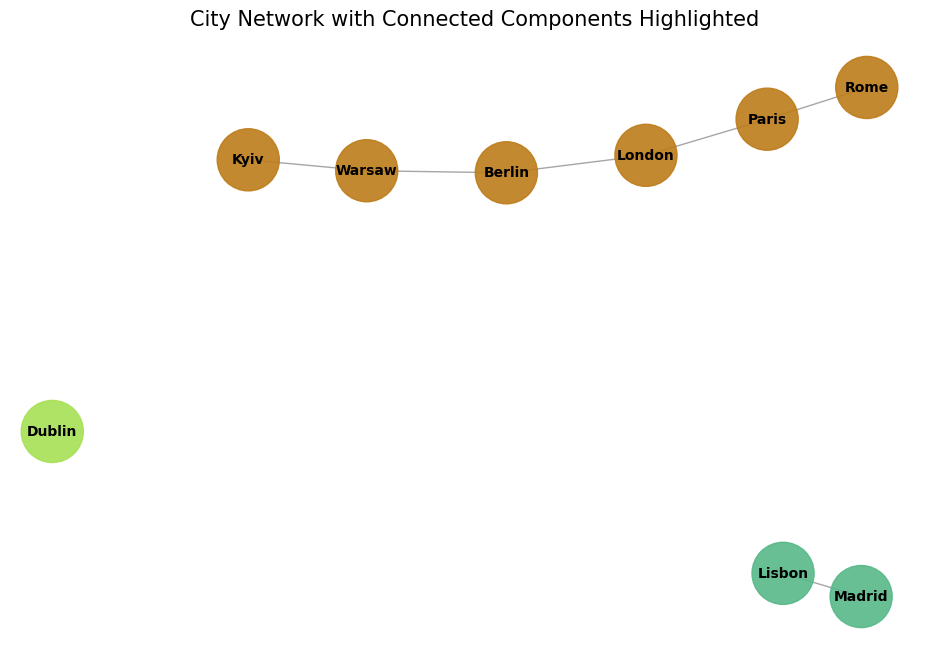

In [26]:
import matplotlib.pyplot as plt
import networkx as nx
import random

# Create a graph for visualization (undirected for components, but store as directed first for clarity)
# We'll treat the city_graph as undirected for connected components
G_vis = nx.Graph(city_graph)

# Define node positions for visualization (using spring layout for general graphs)
pos_vis = nx.spring_layout(G_vis, seed=42) # For reproducible layout

plt.figure(figsize=(12, 8))

# Generate a unique color for each component
colors = ["#%06x" % random.randint(0, 0xFFFFFF) for _ in connected_components]

# Draw nodes for each component with its unique color
node_colors_map = {}
for i, component in enumerate(connected_components):
    for city in component:
        node_colors_map[city] = colors[i]

nx.draw_networkx_nodes(G_vis, pos_vis, node_color=[node_colors_map.get(node, 'lightgray') for node in G_vis.nodes()], node_size=2000, alpha=0.9)
nx.draw_networkx_edges(G_vis, pos_vis, edge_color='gray', width=1.0, alpha=0.7)
nx.draw_networkx_labels(G_vis, pos_vis, font_size=10, font_weight='bold')

plt.title('City Network with Connected Components Highlighted', size=15)
plt.axis('off')
plt.show()